In [1]:
# classify photos with a pretrained model

In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

IMAGE_SIZE = (160,160)

In [4]:
PHOTOS = "./images/"

In [6]:
# load the pretrained model

model = keras.applications.MobileNetV2(weights="imagenet")
print("Number of weights:",model.count_params())

Number of weights: 3538984


Shape: (224, 224, 3)
Batch shape: (1, 224, 224, 3)


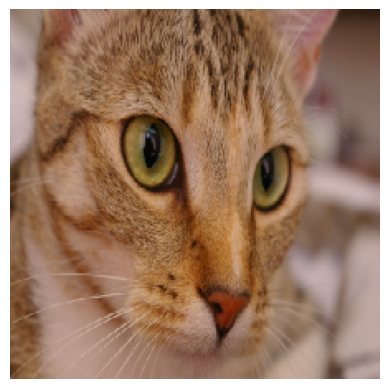

In [7]:
# load images

photo = keras.utils.load_img("./images/cat.png", target_size=(224, 224))
array = keras.utils.img_to_array(photo)
 
print("Shape:", array.shape)

batch = array[np.newaxis, ...]
batch = keras.applications.mobilenet_v2.preprocess_input(batch)
 
print("Batch shape:", batch.shape)
plt.imshow(photo)
plt.axis("off")
plt.show()

In [8]:
# ask the model
probabilities = model.predict(batch)
guesses = keras.applications.mobilenet_v2.decode_predictions(probabilities, top=3)[0]
 
print("GUESSES",guesses,"\n")
 
for label_id, name, score in guesses:
    print(name, ":", round(float(score), 2))

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
GUESSES [('n02124075', 'Egyptian_cat', np.float32(0.58987975)), ('n02123045', 'tabby', np.float32(0.14815785)), ('n02123159', 'tiger_cat', np.float32(0.1363792))] 

Egyptian_cat : 0.59
tabby : 0.15
tiger_cat : 0.14


In [9]:
# try all four photos

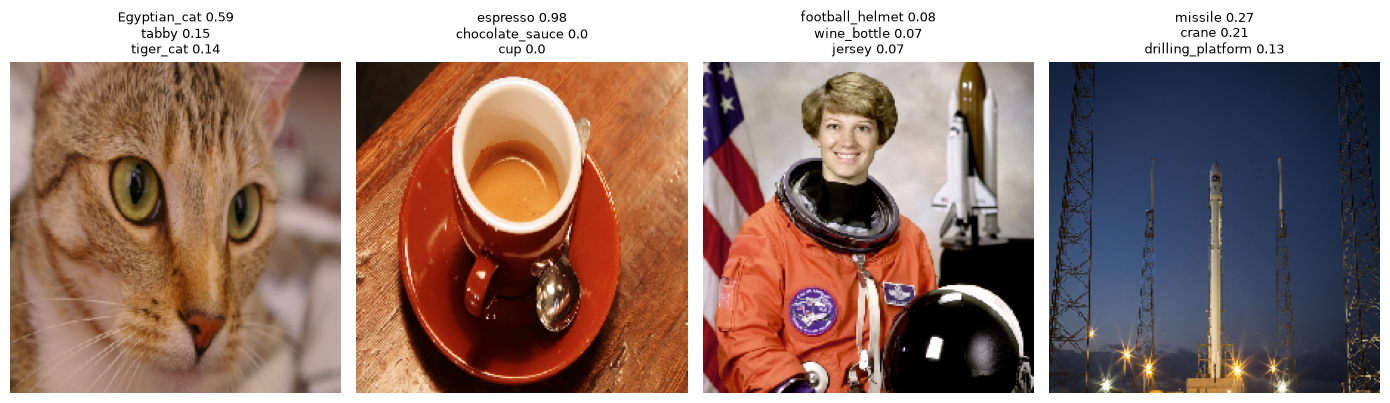

In [10]:
def classify(path):

    photo = keras.utils.load_img(path, target_size=(224, 224))

    batch = keras.applications.mobilenet_v2.preprocess_input(keras.utils.img_to_array(photo)[np.newaxis, ...])

    guesses = keras.applications.mobilenet_v2.decode_predictions(model.predict(batch, verbose=0), top=3)[0]

    return photo, guesses
 
names = ["cat.png", "coffee.png", "astronaut.png", "rocket.jpg"]
 
fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for ax, name in zip(axes, names):

    photo, guesses = classify(PHOTOS + name)

    ax.imshow(photo)

    ax.axis("off")

    text = "\n".join(label + " " + str(round(float(score), 2)) for _, label, score in guesses)

    ax.set_title(text, fontsize=9)

plt.tight_layout()

plt.show()
 